# ORICEAN — Sentinel-1 SAR Oil Spill Classifier

## Project-ready Colab training notebook

This notebook is adapted from the uploaded Kaggle training notebook. The original notebook:
- uses Sentinel-1 SAR oil/no-oil image classes,
- converts images to grayscale and then RGB,
- resizes to 224×224,
- compares ResNet50, EfficientNet-B0 and MobileNetV3-Large,
- and performs ensemble/distillation.

For the ORICEAN MVP, this version intentionally simplifies training to **one deployable model: MobileNetV3-Large**.

### Why this version?
- Works in **Google Colab**
- Uses GPU when available
- Avoids training three large models + ensemble + distillation
- Saves one deployable `.pth` file
- Saves preprocessing metadata
- Includes standalone inference
- Is designed to later integrate with:
  **GEE Sentinel-1 → tiled SAR images → classifier → oil probability map**

> Important: this is an image classifier. It predicts whether a SAR tile contains oil; it does not perform pixel-level segmentation.


## 1. Colab setup

In Colab, enable:

**Runtime → Change runtime type → GPU**


In [1]:
!pip -q install timm kaggle tqdm scikit-learn seaborn

In [2]:
import os
import json
import random
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
import timm

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 2. Download the Kaggle dataset

The source notebook uses:

`harikrishnacs/sentinel-1-sar-oil-spill-detection-dataset`

### First-time Colab setup
1. Go to Kaggle → Settings → API → Create New Token
2. Upload the downloaded `kaggle.json` when prompted below.

Do **not** commit `kaggle.json` to GitHub.


In [3]:
from google.colab import files

print("Upload kaggle.json")
uploaded = files.upload()

if "kaggle.json" not in uploaded:
    raise RuntimeError("Please upload kaggle.json")

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

DATASET_SLUG = "harikrishnacs/sentinel-1-sar-oil-spill-detection-dataset"
DATA_ROOT = Path("/content/oricean_data")

if not DATA_ROOT.exists():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    !kaggle datasets download -d $DATASET_SLUG -p /content/oricean_data --unzip
else:
    print("Dataset directory already exists:", DATA_ROOT)

Upload kaggle.json


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/harikrishnacs/sentinel-1-sar-oil-spill-detection-dataset
License(s): CC-BY-SA-4.0
100% 63.8M/63.8M [00:04<00:00, 16.5MB/s]



## 3. Locate the two classes automatically

The original notebook uses:

- `S1SAR_UnBalanced_400by400_Class_0/0` → **No Oil**
- `S1SAR_UnBalanced_400by400_Class_1/1` → **Oil Spill**


In [4]:
from pathlib import Path

DATA_ROOT = Path("/content/oricean_data/kaggle/data")

CLASS_0_DIR = DATA_ROOT / "Class_0"
CLASS_1_DIR = DATA_ROOT / "Class_1"

print("No Oil folder:", CLASS_0_DIR)
print("Oil Spill folder:", CLASS_1_DIR)

VALID_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

image_paths = []
labels = []

# Class 0 → No Oil
for p in CLASS_0_DIR.iterdir():
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS:
        image_paths.append(str(p))
        labels.append(0)

# Class 1 → Oil Spill
for p in CLASS_1_DIR.iterdir():
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS:
        image_paths.append(str(p))
        labels.append(1)

print("\nDataset Summary")
print("----------------")
print("Total images:", len(image_paths))
print("Class 0 / No Oil:", labels.count(0))
print("Class 1 / Oil Spill:", labels.count(1))

assert len(image_paths) > 0, "No images found"
assert len(set(labels)) == 2, "Both classes are required"

No Oil folder: /content/oricean_data/kaggle/data/Class_0
Oil Spill folder: /content/oricean_data/kaggle/data/Class_1

Dataset Summary
----------------
Total images: 5538
Class 0 / No Oil: 3695
Class 1 / Oil Spill: 1843


## 4. Stratified train / validation / test split

Same 60 / 20 / 20 structure as the source notebook.


In [5]:
X_temp, X_test, y_temp, y_test = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    stratify=labels,
    random_state=SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    stratify=y_temp,
    random_state=SEED
)

print(f"Train: {len(X_train)}")
print(f"Validation: {len(X_val)}")
print(f"Test: {len(X_test)}")

Train: 3322
Validation: 1108
Test: 1108


## 5. Dataset and preprocessing

This preserves the source notebook's important preprocessing assumptions:

`image → grayscale → RGB → 224×224 → tensor → ImageNet normalization`

The grayscale image is duplicated into 3 channels because MobileNetV3-Large expects RGB input.


In [6]:
class SAROilDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("L")
        image = image.convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label


IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.05, contrast=0.05),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = SAROilDataset(X_train, y_train, train_transform)
val_dataset = SAROilDataset(X_val, y_val, eval_transform)
test_dataset = SAROilDataset(X_test, y_test, eval_transform)

## 6. Handle class imbalance and create DataLoaders

In [7]:
train_counts = np.bincount(y_train, minlength=2)
class_weights_np = 1.0 / train_counts
sample_weights = np.array([class_weights_np[label] for label in y_train])

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

class_weights = torch.tensor(
    len(y_train) / (2 * train_counts),
    dtype=torch.float32
).to(DEVICE)

print("Class counts:", train_counts)
print("Class weights:", class_weights)

Class counts: [2217 1105]
Class weights: tensor([0.7492, 1.5032], device='cuda:0')


## 7. Build ORICEAN MVP model

### Selected architecture: MobileNetV3-Large

This is deliberately simpler than reproducing the source notebook's full ResNet + EfficientNet + MobileNet ensemble and distillation pipeline.

It is a better first production model for ORICEAN because:
- relatively lightweight,
- fast inference,
- easier to deploy in FastAPI,
- suitable for scanning many SAR tiles.


In [8]:
MODEL_NAME = "mobilenetv3_large_100"

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=2
).to(DEVICE)

print("Model:", MODEL_NAME)

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.1MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: mobilenetv3_large_100


## 8. Training configuration

In [9]:
EPOCHS = 12
LEARNING_RATE = 3e-4
PATIENCE = 4

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

MODEL_DIR = Path("/content/oricean_model")
MODEL_DIR.mkdir(exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "oricean_oil_classifier_mobilenetv3_large.pth"
METADATA_PATH = MODEL_DIR / "model_metadata.json"

## 9. Training loop with early stopping

In [10]:
def evaluate(model, loader):
    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(DEVICE)
            targets = targets.to(DEVICE)

            logits = model(images)
            loss = criterion(logits, targets)

            probabilities = torch.softmax(logits, dim=1)
            predictions = probabilities.argmax(dim=1)

            total_loss += loss.item() * targets.size(0)
            total_samples += targets.size(0)

            y_true.extend(targets.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())
            y_prob.extend(probabilities[:, 1].cpu().numpy())

    metrics = {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    if len(set(y_true)) == 2:
        metrics["roc_auc"] = roc_auc_score(y_true, y_prob)
    else:
        metrics["roc_auc"] = None

    return metrics


best_f1 = -1
patience_counter = 0
history = {
    "train_loss": [],
    "val_loss": [],
    "val_f1": [],
    "val_accuracy": []
}

for epoch in range(1, EPOCHS + 1):
    model.train()

    running_loss = 0.0
    total = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")

    for images, targets in progress:
        images = images.to(DEVICE)
        targets = targets.to(DEVICE)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.size(0)
        total += targets.size(0)

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / total
    val_metrics = evaluate(model, val_loader)

    scheduler.step(val_metrics["f1"])

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_metrics["loss"])
    history["val_f1"].append(val_metrics["f1"])
    history["val_accuracy"].append(val_metrics["accuracy"])

    print(
        f"Epoch {epoch}: "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_metrics['loss']:.4f} | "
        f"val_acc={val_metrics['accuracy']:.4f} | "
        f"val_f1={val_metrics['f1']:.4f}"
    )

    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]
        patience_counter = 0

        torch.save({
            "architecture": MODEL_NAME,
            "num_classes": 2,
            "class_names": ["No Oil", "Oil Spill"],
            "state_dict": model.state_dict()
        }, BEST_MODEL_PATH)

        print(f"✓ Best model saved → {BEST_MODEL_PATH}")

    else:
        patience_counter += 1
        print(f"No improvement: {patience_counter}/{PATIENCE}")

        if patience_counter >= PATIENCE:
            print("Early stopping.")
            break

Epoch 1/12:   0%|          | 0/104 [00:00<?, ?it/s]

Epoch 1: train_loss=0.8149 | val_loss=0.3113 | val_acc=0.9341 | val_f1=0.9036
✓ Best model saved → /content/oricean_model/oricean_oil_classifier_mobilenetv3_large.pth


Epoch 2/12:   0%|          | 0/104 [00:00<?, ?it/s]

Epoch 2: train_loss=0.2631 | val_loss=0.3845 | val_acc=0.9052 | val_f1=0.8743
No improvement: 1/4


Epoch 3/12:   0%|          | 0/104 [00:00<?, ?it/s]

...

Epoch 11/12:   0%|          | 0/104 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x788e52be8f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x788e52be8f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 11: train_loss=0.0487 | val_loss=0.1413 | val_acc=0.9648 | val_f1=0.9493
No improvement: 2/4


Epoch 12/12:   0%|          | 0/104 [00:00<?, ?it/s]

Epoch 12: train_loss=0.0377 | val_loss=0.1460 | val_acc=0.9666 | val_f1=0.9490
No improvement: 3/4


## 10. Final test evaluation

For ORICEAN, pay special attention to **recall and F1 for the Oil Spill class**, not only overall accuracy.


In [11]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["state_dict"])
model.eval()

test_metrics = evaluate(model, test_loader)

print("\n===== FINAL TEST RESULTS =====")
for key in ["loss", "accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"{key}: {test_metrics.get(key)}")

print("\nClassification report:")
print(
    classification_report(
        test_metrics["y_true"],
        test_metrics["y_pred"],
        target_names=["No Oil", "Oil Spill"],
        zero_division=0
    )
)


===== FINAL TEST RESULTS =====
loss: 0.08927730438723952
accuracy: 0.9747292418772563
precision: 0.9571045576407506
recall: 0.967479674796748
f1: 0.9622641509433962
roc_auc: 0.9972899728997289

Classification report:
              precision    recall  f1-score   support

      No Oil       0.98      0.98      0.98       739
   Oil Spill       0.96      0.97      0.96       369

    accuracy                           0.97      1108
   macro avg       0.97      0.97      0.97      1108
weighted avg       0.97      0.97      0.97      1108



## 11. Visualize results

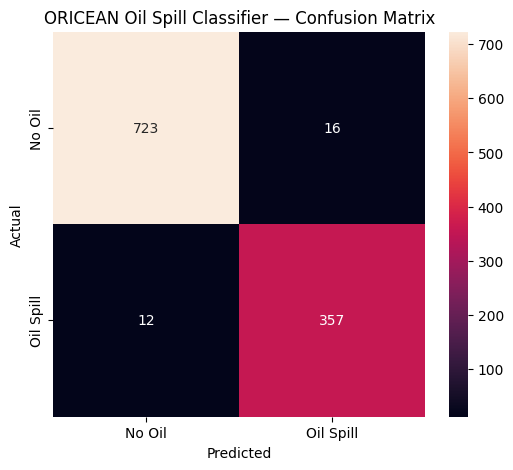

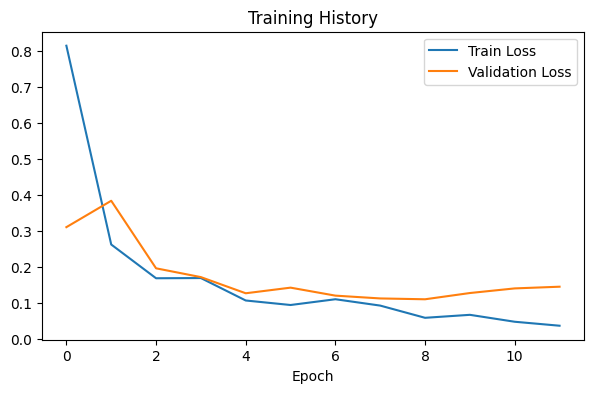

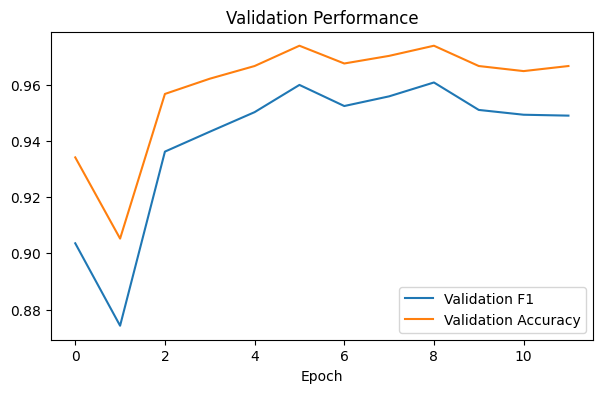

In [12]:
cm = confusion_matrix(test_metrics["y_true"], test_metrics["y_pred"])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No Oil", "Oil Spill"],
    yticklabels=["No Oil", "Oil Spill"]
)
plt.title("ORICEAN Oil Spill Classifier — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Training History")
plt.xlabel("Epoch")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history["val_f1"], label="Validation F1")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.title("Validation Performance")
plt.xlabel("Epoch")
plt.show()

## 12. Save model metadata

This metadata should travel with the `.pth` file into your backend repository.


In [13]:
metadata = {
    "project": "ORICEAN",
    "task": "Binary Sentinel-1 SAR oil spill tile classification",
    "architecture": MODEL_NAME,
    "num_classes": 2,
    "class_names": ["No Oil", "Oil Spill"],
    "positive_class": 1,
    "input_size": [224, 224],
    "source_image_processing": [
        "Open image",
        "Convert to grayscale (L)",
        "Convert grayscale to RGB",
        "Resize to 224x224",
        "Convert to tensor",
        "Normalize with ImageNet mean/std"
    ],
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },
    "dataset_source": DATASET_SLUG,
    "limitations": [
        "Classification model, not segmentation",
        "Positive predictions identify candidate SAR tiles rather than exact pixel-level slick boundaries",
        "GEE Sentinel-1 production preprocessing must be validated against the training dataset representation"
    ]
}

with open(METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

print(METADATA_PATH)
print(json.dumps(metadata, indent=2))

/content/oricean_model/model_metadata.json
{
  "project": "ORICEAN",
  "task": "Binary Sentinel-1 SAR oil spill tile classification",
  "architecture": "mobilenetv3_large_100",
  "num_classes": 2,
  "class_names": [
    "No Oil",
    "Oil Spill"
  ],
  "positive_class": 1,
  "input_size": [
    224,
    224
  ],
  "source_image_processing": [
    "Open image",
    "Convert to grayscale (L)",
    "Convert grayscale to RGB",
    "Resize to 224x224",
    "Convert to tensor",
    "Normalize with ImageNet mean/std"
  ],
  "normalization": {
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ]
  },
  "dataset_source": "harikrishnacs/sentinel-1-sar-oil-spill-detection-dataset",
  "limitations": [
    "Classification model, not segmentation",
    "Positive predictions identify candidate SAR tiles rather than exact pixel-level slick boundaries",
    "GEE Sentinel-1 production preprocessing must be validated against the training data

## 13. Standalone inference test

This is close to what your future `predictor.py` will do in the backend.


Sample: /content/oricean_data/kaggle/data/Class_0/class_0_02777.jpg
{'prediction': 'No Oil', 'oil_probability': 4.6572946388323544e-08, 'no_oil_probability': 1.0}


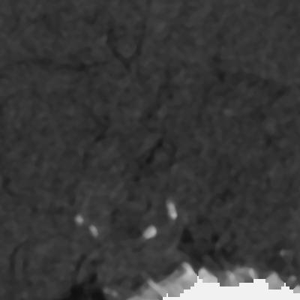

In [14]:
INFERENCE_TRANSFORM = eval_transform

def load_oricean_model(model_path=BEST_MODEL_PATH):
    checkpoint = torch.load(model_path, map_location=DEVICE)

    inference_model = timm.create_model(
        checkpoint["architecture"],
        pretrained=False,
        num_classes=checkpoint["num_classes"]
    )

    inference_model.load_state_dict(checkpoint["state_dict"])
    inference_model.to(DEVICE)
    inference_model.eval()

    return inference_model, checkpoint


def predict_image(image_path, inference_model):
    image = Image.open(image_path).convert("L").convert("RGB")
    tensor = INFERENCE_TRANSFORM(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = inference_model(tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    predicted_class = int(np.argmax(probabilities))

    return {
        "prediction": ["No Oil", "Oil Spill"][predicted_class],
        "oil_probability": float(probabilities[1]),
        "no_oil_probability": float(probabilities[0])
    }


inference_model, checkpoint = load_oricean_model()

sample_image = X_test[0]
result = predict_image(sample_image, inference_model)

print("Sample:", sample_image)
print(result)

display(Image.open(sample_image).resize((300, 300)))

## 14. Download trained model artifacts

Download both files and place them locally in:

```text
backend/ml/models/
├── oricean_oil_classifier_mobilenetv3_large.pth
└── model_metadata.json
```


In [ ]:
from google.colab import files

files.download(str(BEST_MODEL_PATH))
files.download(str(METADATA_PATH))

# ORICEAN production pipeline after training

```text
Google Earth Engine
        ↓
Sentinel-1 SAR scene
        ↓
AOI clipping
        ↓
Georeferenced tile generation
        ↓
Apply the SAME validated preprocessing
        ↓
MobileNetV3-Large classifier
        ↓
Oil probability per tile
        ↓
Probability grid / heatmap
        ↓
Group adjacent positive tiles
        ↓
Candidate spill region
        ↓
Source reconstruction
        ↓
AIS vessel attribution
```

## Next engineering task

After successfully training and downloading the model:

1. Test this `.pth` locally on one SAR image.
2. Extract the inference code into `backend/ml/inference/predictor.py`.
3. Build `app/services/ml_service.py`.
4. Only then connect GEE-generated SAR tiles to the classifier.

> Do not assume a raw GEE export is numerically identical to the training images. Validate the representation and preprocessing before relying on production predictions.


In [15]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

model = model.to(device)
model.eval()

Using device: cuda


MobileNetV3(
  (conv_stem): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
    (drop): Identity()
    (act): Hardswish()
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
        (bn1): BatchNormAct2d(
          16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): ReLU(inplace=True)
        )
        (aa): Identity()
        (se): Identity()
        (conv_pw): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2): BatchNormAct2d(
          16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): Identity()
        )
        (drop_path): Identity()
      )
    )
    (1): Sequential(
     

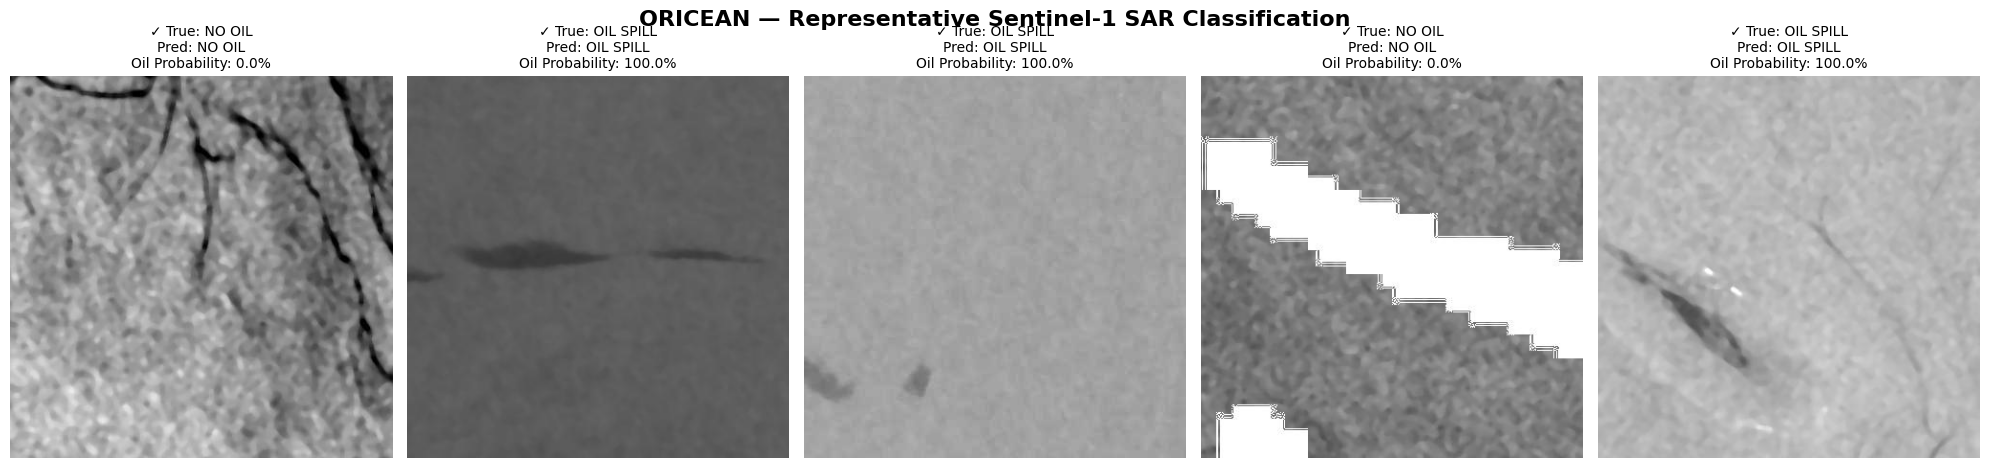

In [16]:
import random
import torch
import matplotlib.pyplot as plt
from PIL import Image

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

# Transform - MUST match training preprocessing
from torchvision import transforms

test_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Separate images by class
oil_indices = [i for i, label in enumerate(labels) if label == 1]
no_oil_indices = [i for i, label in enumerate(labels) if label == 0]

# Pick 3 oil + 2 no-oil
selected_indices = (
    random.sample(oil_indices, 3) +
    random.sample(no_oil_indices, 2)
)

random.shuffle(selected_indices)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, idx in zip(axes, selected_indices):

    image_path = image_paths[idx]
    true_label = labels[idx]

    img = Image.open(image_path).convert("RGB")

    # Preprocess
    input_tensor = test_transform(img).unsqueeze(0).to(device)

    # Predict
    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1)

        oil_probability = probabilities[0][1].item() * 100
        predicted_label = torch.argmax(probabilities, dim=1).item()

    # Labels
    true_text = "OIL SPILL" if true_label == 1 else "NO OIL"
    pred_text = "OIL SPILL" if predicted_label == 1 else "NO OIL"

    # Show original grayscale-like image
    ax.imshow(Image.open(image_path), cmap="gray")

    correct = predicted_label == true_label
    symbol = "✓" if correct else "✗"

    ax.set_title(
        f"{symbol} True: {true_text}\n"
        f"Pred: {pred_text}\n"
        f"Oil Probability: {oil_probability:.1f}%",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "ORICEAN — Representative Sentinel-1 SAR Classification",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Model type: MobileNetV3
Using device: cuda
In-place operations disabled where applicable.

Grad-CAM target layer:
Name: conv_head
Layer: Conv2d(960, 1280, kernel_size=(1, 1), stride=(1, 1))

Grad-CAM initialized successfully!

Testing representative images:
Oil images: 3
No-oil images: 2


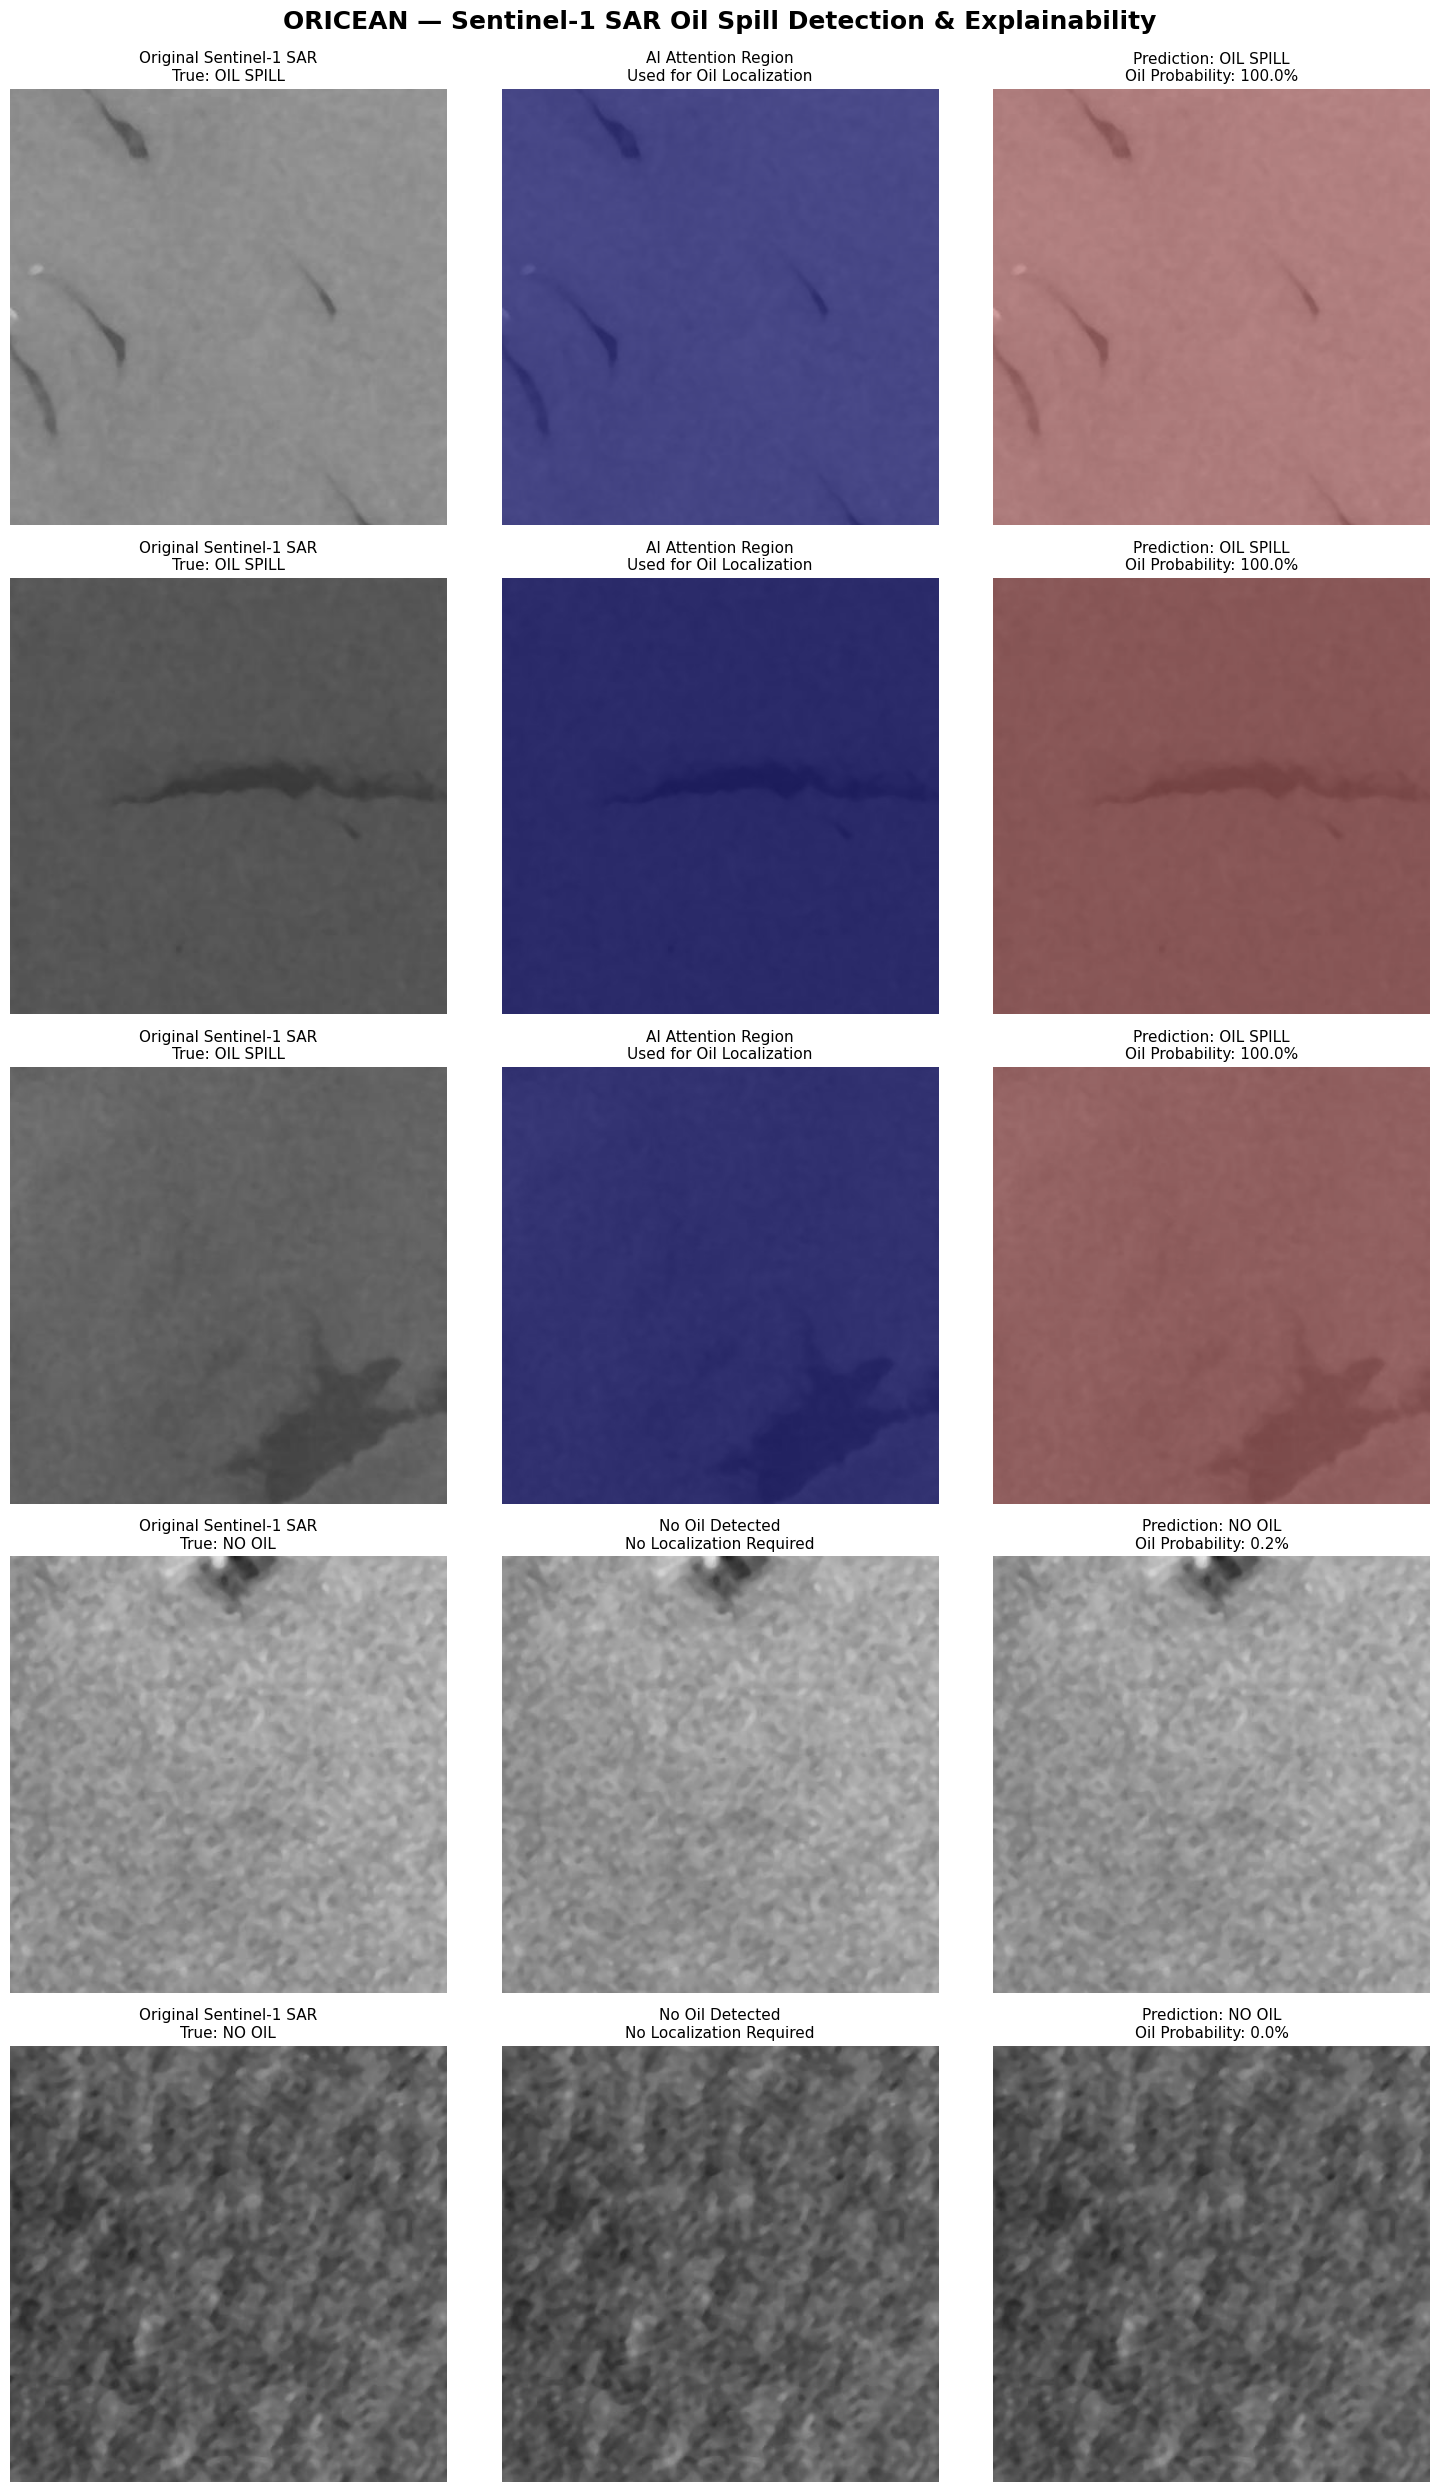


Grad-CAM testing completed successfully!


In [17]:
# ============================================================
# ORICEAN — SENTINEL-1 SAR OIL SPILL CLASSIFICATION
# + GRAD-CAM EXPLAINABILITY
#
# Expected existing variables:
# model
# device
# test_transform
# image_paths
# labels
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import cv2

from PIL import Image


# ============================================================
# 1. MODEL SETUP
# ============================================================

model = model.to(device)
model.eval()

print("Model type:", type(model).__name__)
print("Using device:", device)


# ============================================================
# 2. DISABLE INPLACE OPERATIONS
#
# This prevents MobileNet / Hardswish Grad-CAM errors
# ============================================================

for module in model.modules():

    if hasattr(module, "inplace"):
        try:
            module.inplace = False
        except:
            pass


print("In-place operations disabled where applicable.")


# ============================================================
# 3. FIND LAST CONVOLUTIONAL LAYER AUTOMATICALLY
# ============================================================

target_layer = None
target_layer_name = None

for name, module in model.named_modules():

    if isinstance(module, nn.Conv2d):
        target_layer = module
        target_layer_name = name


if target_layer is None:
    raise RuntimeError("No Conv2D layer found in model.")


print("\nGrad-CAM target layer:")
print("Name:", target_layer_name)
print("Layer:", target_layer)


# ============================================================
# 4. GRAD-CAM CLASS
# ============================================================

class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        # Forward hook
        self.forward_hook = target_layer.register_forward_hook(
            self.save_activation
        )

        # Backward hook
        self.backward_hook = target_layer.register_full_backward_hook(
            self.save_gradient
        )


    def save_activation(self, module, input, output):

        # Clone avoids issues with views/in-place operations
        self.activations = output.clone()


    def save_gradient(self, module, grad_input, grad_output):

        self.gradients = grad_output[0].clone()


    def generate_cam(self, input_tensor, class_idx):

        # Clear previous gradients
        self.model.zero_grad(set_to_none=True)

        # Forward pass
        output = self.model(input_tensor)

        # Score for target class
        class_score = output[:, class_idx]

        # Backward
        class_score.backward(
            torch.ones_like(class_score),
            retain_graph=False
        )

        # Check hooks worked
        if self.gradients is None:
            raise RuntimeError(
                "Gradients were not captured."
            )

        if self.activations is None:
            raise RuntimeError(
                "Activations were not captured."
            )

        gradients = self.gradients
        activations = self.activations

        # Global average pooling of gradients
        weights = torch.mean(
            gradients,
            dim=(2, 3),
            keepdim=True
        )

        # Weighted combination
        cam = torch.sum(
            weights * activations,
            dim=1,
            keepdim=False
        )

        # ReLU
        cam = torch.relu(cam)

        # Convert to numpy
        cam = cam.squeeze().detach().cpu().numpy()

        # Normalize safely
        cam_min = cam.min()
        cam_max = cam.max()

        if cam_max > cam_min:

            cam = (
                cam - cam_min
            ) / (
                cam_max - cam_min
            )

        else:

            cam = np.zeros_like(cam)

        return cam


    def remove_hooks(self):

        self.forward_hook.remove()
        self.backward_hook.remove()


# ============================================================
# 5. INITIALIZE GRAD-CAM
# ============================================================

grad_cam = GradCAM(
    model=model,
    target_layer=target_layer
)

print("\nGrad-CAM initialized successfully!")


# ============================================================
# 6. CREATE OIL-ONLY RED OVERLAY
#
# ONLY strongest Grad-CAM pixels become red.
# Everything else stays unchanged.
# ============================================================

def create_oil_only_overlay(
    original_img,
    cam,
    threshold_percentile=88,
    alpha=0.30,
    min_area=40
):

    # --------------------------------------------------------
    # Convert PIL image to RGB NumPy
    # --------------------------------------------------------

    if isinstance(original_img, Image.Image):

        image = np.array(
            original_img.convert("RGB")
        )

    else:

        image = original_img.copy()

        if image.dtype != np.uint8:

            image = np.clip(
                image * 255,
                0,
                255
            ).astype(np.uint8)


    h, w = image.shape[:2]


    # --------------------------------------------------------
    # Convert CAM safely
    # --------------------------------------------------------

    if hasattr(cam, "detach"):

        cam = cam.detach().cpu().numpy()


    cam = np.squeeze(cam)

    cam = np.asarray(
        cam,
        dtype=np.float32
    )


    # --------------------------------------------------------
    # Resize CAM to original SAR image size
    # --------------------------------------------------------

    cam_resized = cv2.resize(
        cam,
        (w, h),
        interpolation=cv2.INTER_CUBIC
    )


    # --------------------------------------------------------
    # Normalize CAM
    # --------------------------------------------------------

    cam_min = cam_resized.min()
    cam_max = cam_resized.max()

    if cam_max > cam_min:

        cam_normalized = (
            cam_resized - cam_min
        ) / (
            cam_max - cam_min
        )

    else:

        cam_normalized = np.zeros_like(
            cam_resized
        )


    # --------------------------------------------------------
    # Keep ONLY strongest attention pixels
    #
    # 88 percentile = strongest ~12%
    # --------------------------------------------------------

    threshold = np.percentile(
        cam_normalized,
        threshold_percentile
    )


    mask = (
        cam_normalized >= threshold
    ).astype(np.uint8)


    # --------------------------------------------------------
    # Morphological cleanup
    # --------------------------------------------------------

    kernel = np.ones(
        (3, 3),
        np.uint8
    )


    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )


    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )


    # --------------------------------------------------------
    # Remove tiny disconnected regions
    # --------------------------------------------------------

    num_labels, connected_labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )


    clean_mask = np.zeros_like(mask)


    for label_id in range(
        1,
        num_labels
    ):

        area = stats[
            label_id,
            cv2.CC_STAT_AREA
        ]


        if area >= min_area:

            clean_mask[
                connected_labels == label_id
            ] = 1


    mask = clean_mask


    # --------------------------------------------------------
    # Create output image
    # --------------------------------------------------------

    overlay = image.copy().astype(
        np.float32
    )


    # Light coral red
    red_color = np.array(
        [
            255,
            90,
            90
        ],
        dtype=np.float32
    )


    mask_indices = mask.astype(bool)


    # --------------------------------------------------------
    # Blend ONLY oil-region pixels
    # --------------------------------------------------------

    overlay[mask_indices] = (

        (1 - alpha)
        * overlay[mask_indices]

        +

        alpha
        * red_color

    )


    overlay = np.clip(
        overlay,
        0,
        255
    ).astype(np.uint8)


    return overlay, mask


# ============================================================
# 7. SELECT REPRESENTATIVE TEST IMAGES
#
# Tries to choose:
# 3 oil images
# 2 no-oil images
# ============================================================

oil_indices = [
    i
    for i, label in enumerate(labels)
    if label == 1
]


no_oil_indices = [
    i
    for i, label in enumerate(labels)
    if label == 0
]


np.random.seed(42)


selected_oil = np.random.choice(
    oil_indices,
    size=min(3, len(oil_indices)),
    replace=False
).tolist()


selected_no_oil = np.random.choice(
    no_oil_indices,
    size=min(2, len(no_oil_indices)),
    replace=False
).tolist()


selected_indices = (
    selected_oil
    +
    selected_no_oil
)


print("\nTesting representative images:")
print(
    "Oil images:",
    len(selected_oil)
)

print(
    "No-oil images:",
    len(selected_no_oil)
)


# ============================================================
# 8. TEST AND VISUALIZE
# ============================================================

fig, axes = plt.subplots(
    len(selected_indices),
    3,
    figsize=(
        15,
        5 * len(selected_indices)
    )
)


if len(selected_indices) == 1:

    axes = np.expand_dims(
        axes,
        axis=0
    )


fig.suptitle(
    "ORICEAN — Sentinel-1 SAR Oil Spill Detection & Explainability",
    fontsize=18,
    fontweight="bold",
    y=0.995
)


for row, idx in enumerate(
    selected_indices
):


    # --------------------------------------------------------
    # Load image
    # --------------------------------------------------------

    image_path = image_paths[idx]

    true_label = labels[idx]


    original_img = Image.open(
        image_path
    ).convert("RGB")


    # --------------------------------------------------------
    # Preprocess
    # --------------------------------------------------------

    input_tensor = test_transform(
        original_img
    ).unsqueeze(0).to(device)


    # --------------------------------------------------------
    # Classification
    #
    # Do separately with no_grad
    # --------------------------------------------------------

    with torch.no_grad():

        output = model(
            input_tensor
        )


        probabilities = torch.softmax(
            output,
            dim=1
        )[0]


        oil_probability = (
            probabilities[1]
            .item()
            * 100
        )


        predicted_class = torch.argmax(
            probabilities
        ).item()


    # --------------------------------------------------------
    # CLASSIFICATION RESULT
    # --------------------------------------------------------

    if predicted_class == 1:

        prediction_text = "OIL SPILL"

    else:

        prediction_text = "NO OIL"


    true_text = (
        "OIL SPILL"
        if true_label == 1
        else "NO OIL"
    )


    # ========================================================
    # IMPORTANT:
    #
    # NO OIL -> ORIGINAL IMAGE ONLY
    # OIL -> GENERATE CAM + RED OIL REGION
    # ========================================================

    if predicted_class == 0:


        # ----------------------------------------------------
        # NO OIL
        # NO RED
        # ----------------------------------------------------

        final_overlay = np.array(
            original_img.convert("RGB")
        )


        oil_mask = np.zeros(
            (
                original_img.height,
                original_img.width
            ),
            dtype=np.uint8
        )


        cam_display = np.zeros(
            (
                original_img.height,
                original_img.width
            ),
            dtype=np.float32
        )


    else:


        # ----------------------------------------------------
        # OIL DETECTED
        # Generate Grad-CAM
        # ----------------------------------------------------

        cam = grad_cam.generate_cam(
            input_tensor,
            class_idx=1
        )


        # Resize CAM for display

        cam_display = cv2.resize(
            cam.astype(np.float32),
            (
                original_img.width,
                original_img.height
            ),
            interpolation=cv2.INTER_CUBIC
        )


        # Create selective red overlay

        final_overlay, oil_mask = (
            create_oil_only_overlay(

                original_img=original_img,

                cam=cam,

                threshold_percentile=88,

                alpha=0.30,

                min_area=40

            )
        )


    # ========================================================
    # DISPLAY
    # ========================================================


    # --------------------------------------------------------
    # COLUMN 1: ORIGINAL
    # --------------------------------------------------------

    axes[row, 0].imshow(
        original_img
    )


    axes[row, 0].set_title(

        f"Original Sentinel-1 SAR\n"
        f"True: {true_text}",

        fontsize=11

    )


    axes[row, 0].axis("off")


    # --------------------------------------------------------
    # COLUMN 2: GRAD-CAM
    # --------------------------------------------------------

    if predicted_class == 1:


        axes[row, 1].imshow(
            original_img,
            cmap="gray"
        )


        axes[row, 1].imshow(
            cam_display,
            cmap="jet",
            alpha=0.50
        )


        axes[row, 1].set_title(
            "AI Attention Region\n"
            "Used for Oil Localization",
            fontsize=11
        )


    else:


        axes[row, 1].imshow(
            original_img
        )


        axes[row, 1].set_title(
            "No Oil Detected\n"
            "No Localization Required",
            fontsize=11
        )


    axes[row, 1].axis("off")


    # --------------------------------------------------------
    # COLUMN 3: FINAL RESULT
    # --------------------------------------------------------

    axes[row, 2].imshow(
        final_overlay
    )


    axes[row, 2].set_title(

        f"Prediction: {prediction_text}\n"
        f"Oil Probability: {oil_probability:.1f}%",

        fontsize=11

    )


    axes[row, 2].axis("off")


plt.tight_layout()

plt.show()


# ============================================================
# 9. CLEAN UP GRAD-CAM HOOKS
# ============================================================

grad_cam.remove_hooks()

print("\nGrad-CAM testing completed successfully!")

In [18]:
for name, module in model.named_modules():
    if isinstance(module, nn.Conv2d):
        print(name, "->", module)

conv_stem -> Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
blocks.0.0.conv_dw -> Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
blocks.0.0.conv_pw -> Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
blocks.1.0.conv_pw -> Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
blocks.1.0.conv_dw -> Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=64, bias=False)
blocks.1.0.conv_pwl -> Conv2d(64, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)
blocks.1.1.conv_pw -> Conv2d(24, 72, kernel_size=(1, 1), stride=(1, 1), bias=False)
blocks.1.1.conv_dw -> Conv2d(72, 72, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=72, bias=False)
blocks.1.1.conv_pwl -> Conv2d(72, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)
blocks.2.0.conv_pw -> Conv2d(24, 72, kernel_size=(1, 1), stride=(1, 1), bias=False)
blocks.2.0.conv_dw -> Conv2d(72, 72, kernel_size=(5, 5), stride=(2, 2),

In [19]:
target_layer = None
target_layer_name = None

for name, module in model.named_modules():

    if isinstance(module, nn.Conv2d) and name != "conv_head":
        target_layer = module
        target_layer_name = name

print("Selected Grad-CAM layer:")
print(target_layer_name)
print(target_layer)

Selected Grad-CAM layer:
blocks.6.0.conv
Conv2d(160, 960, kernel_size=(1, 1), stride=(1, 1), bias=False)


Model type: MobileNetV3
Using device: cuda
Inplace operations disabled.

Available convolution layers:

0: conv_stem -> Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
1: blocks.0.0.conv_dw -> Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
2: blocks.0.0.conv_pw -> Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
3: blocks.1.0.conv_pw -> Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
4: blocks.1.0.conv_dw -> Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=64, bias=False)
5: blocks.1.0.conv_pwl -> Conv2d(64, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)
6: blocks.1.1.conv_pw -> Conv2d(24, 72, kernel_size=(1, 1), stride=(1, 1), bias=False)
7: blocks.1.1.conv_dw -> Conv2d(72, 72, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=72, bias=False)
8: blocks.1.1.conv_pwl -> Conv2d(72, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)
9: blocks.2.0.conv_pw ->

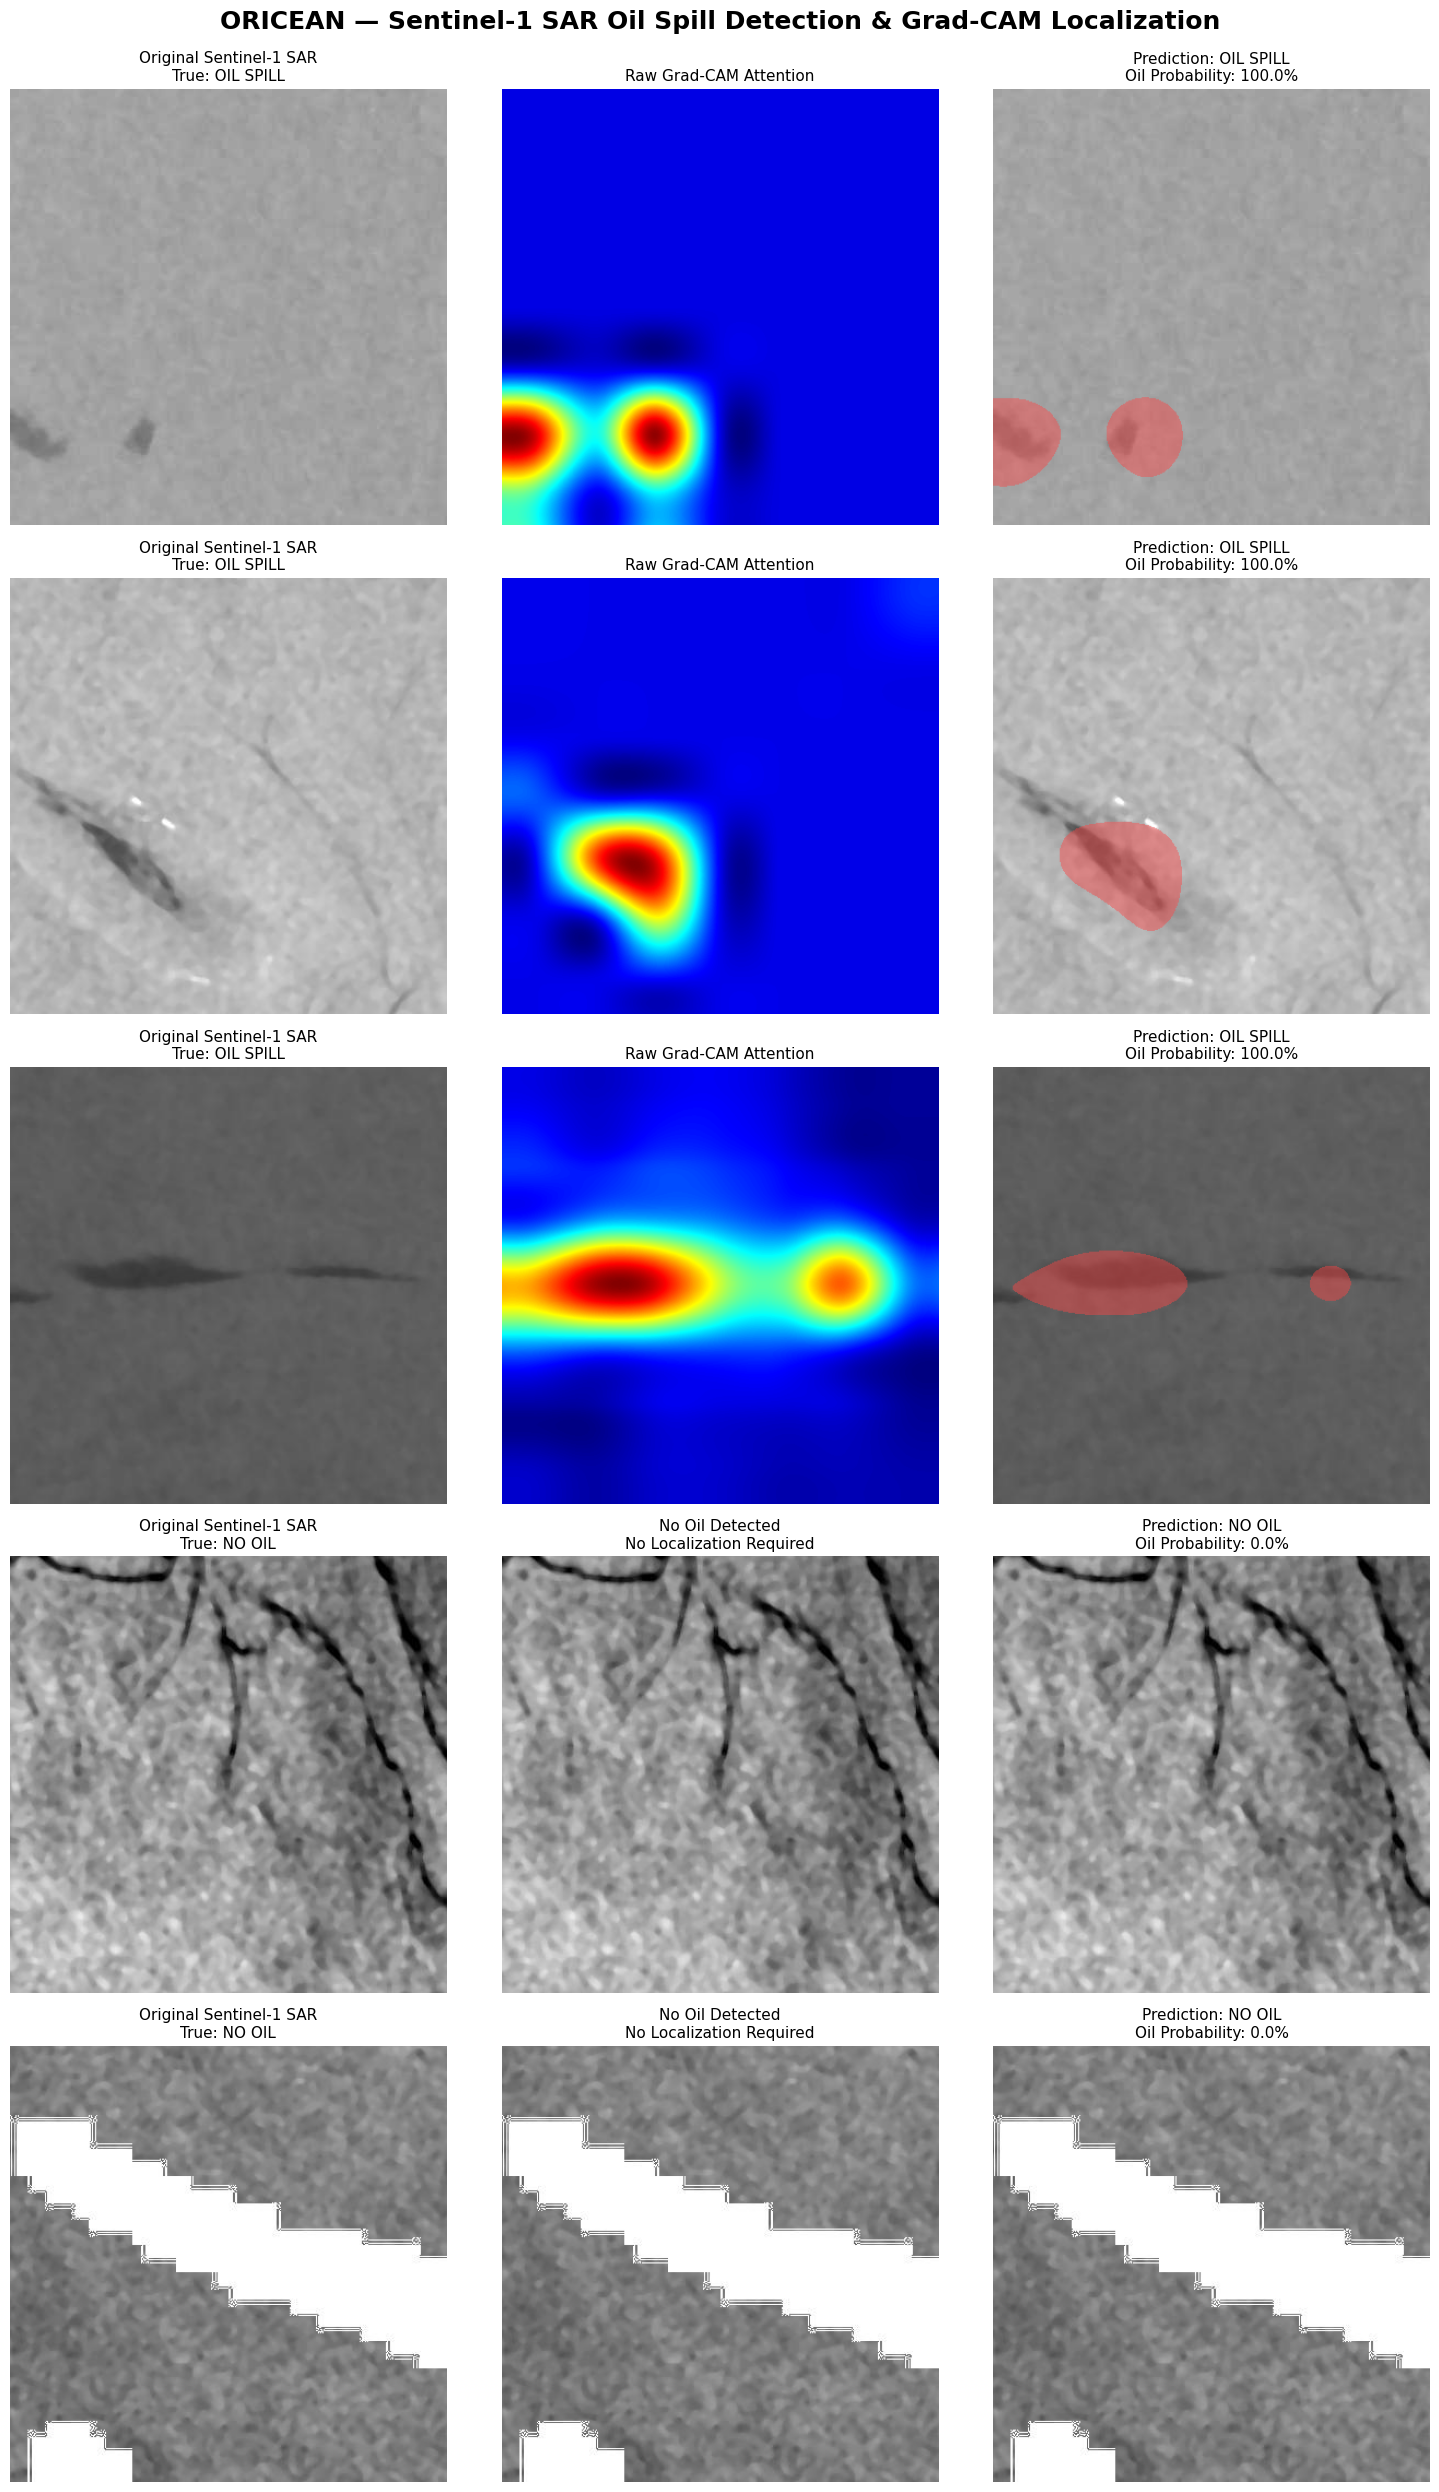

In [22]:
# ============================================================
# ORICEAN — SENTINEL-1 SAR OIL SPILL DETECTION
# + GRAD-CAM DEBUGGING + LOCALIZED RED OVERLAY
#
# This cell:
# 1. Automatically selects a better Grad-CAM layer
# 2. Prevents MobileNetV3 inplace hook errors
# 3. Predicts Oil / No Oil
# 4. Shows RAW Grad-CAM heatmap
# 5. Thresholds only strong attention regions
# 6. Applies red ONLY to localized candidate pixels
# 7. Never applies red for NO OIL predictions
# ============================================================


import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import random


# ============================================================
# 1. DEVICE + MODEL
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

print("Model type:", type(model).__name__)
print("Using device:", device)


# ============================================================
# 2. DISABLE INPLACE OPERATIONS
#
# Important for MobileNetV3 + Grad-CAM hooks
# ============================================================

for module in model.modules():

    if hasattr(module, "inplace"):

        try:
            module.inplace = False
        except:
            pass


print("Inplace operations disabled.")


# ============================================================
# 3. FIND CONVOLUTION LAYERS
# ============================================================

conv_layers = []

for name, module in model.named_modules():

    if isinstance(module, nn.Conv2d):

        conv_layers.append((name, module))


print("\nAvailable convolution layers:\n")

for i, (name, module) in enumerate(conv_layers):

    print(f"{i}: {name} -> {module}")


# ============================================================
# 4. SELECT BETTER GRAD-CAM LAYER
#
# Avoid conv_head because it can be too close to the classifier.
# Select the LAST convolution BEFORE conv_head.
# ============================================================

target_layer = None
target_layer_name = None


for name, module in conv_layers:

    # Skip final classification convolution
    if name != "conv_head":

        target_layer = module
        target_layer_name = name


# Fallback
if target_layer is None:

    target_layer_name, target_layer = conv_layers[-1]


print("\n" + "=" * 60)
print("Selected Grad-CAM target layer:")
print("Name:", target_layer_name)
print("Layer:", target_layer)
print("=" * 60)


# ============================================================
# 5. CUSTOM GRAD-CAM
# ============================================================

class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None


        self.forward_handle = (
            target_layer.register_forward_hook(
                self.forward_hook
            )
        )


        self.backward_handle = (
            target_layer.register_full_backward_hook(
                self.backward_hook
            )
        )


    def forward_hook(self, module, inputs, output):

        self.activations = output.detach().clone()


    def backward_hook(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradients = (
            grad_output[0].detach().clone()
        )


    def generate_cam(
        self,
        input_tensor,
        target_class=1
    ):

        # Clear previous gradients
        self.model.zero_grad()


        # Forward
        output = self.model(input_tensor)


        # Handle models returning tuples
        if isinstance(output, tuple):

            output = output[0]


        # Score for target class
        score = output[:, target_class]


        # Backpropagation
        score.backward()


        # Safety check
        if self.activations is None:

            raise RuntimeError(
                "Grad-CAM activations were not captured."
            )


        if self.gradients is None:

            raise RuntimeError(
                "Grad-CAM gradients were not captured."
            )


        activations = self.activations
        gradients = self.gradients


        # ----------------------------------------------------
        # Global Average Pooling of gradients
        # ----------------------------------------------------

        weights = torch.mean(
            gradients,
            dim=(2, 3),
            keepdim=True
        )


        # ----------------------------------------------------
        # Weighted activation maps
        # ----------------------------------------------------

        cam = torch.sum(
            weights * activations,
            dim=1
        )


        # ReLU
        cam = F.relu(cam)


        # Convert to NumPy
        cam = (
            cam
            .squeeze()
            .detach()
            .cpu()
            .numpy()
        )


        # ----------------------------------------------------
        # Normalize
        # ----------------------------------------------------

        cam_min = np.min(cam)
        cam_max = np.max(cam)


        if cam_max - cam_min > 1e-8:

            cam = (
                cam - cam_min
            ) / (
                cam_max - cam_min
            )

        else:

            cam = np.zeros_like(cam)


        return cam


# Initialize
grad_cam = GradCAM(
    model,
    target_layer
)

print("\nGrad-CAM initialized successfully!")


# ============================================================
# 6. PREPROCESS IMAGE
# ============================================================

def preprocess_image(image):

    image = image.convert("RGB")


    # Use your existing test transform
    if "test_transform" in globals():

        tensor = test_transform(image)

    else:

        # Fallback
        image = image.resize((224, 224))

        image_array = (
            np.array(image)
            .astype(np.float32)
            / 255.0
        )

        tensor = torch.tensor(
            image_array
        ).permute(2, 0, 1)


    return (
        tensor
        .unsqueeze(0)
        .to(device)
    )


# ============================================================
# 7. PREDICT IMAGE
# ============================================================

def predict_image(image_path):

    image = (
        Image
        .open(image_path)
        .convert("RGB")
    )


    input_tensor = preprocess_image(image)


    with torch.no_grad():

        output = model(input_tensor)


        if isinstance(output, tuple):

            output = output[0]


        probabilities = torch.softmax(
            output,
            dim=1
        )


        predicted_class = (
            torch.argmax(
                probabilities,
                dim=1
            )
            .item()
        )


        oil_probability = (
            probabilities[0, 1]
            .item()
        )


    return (
        image,
        input_tensor,
        predicted_class,
        oil_probability
    )


# ============================================================
# 8. CREATE LOCALIZED MASK
#
# IMPORTANT:
# This function receives the actual CAM.
# cam_resized exists ONLY inside this function
# and is returned explicitly.
# ============================================================

def create_localized_oil_mask(
    original_img,
    cam,
    percentile_threshold=95,
    min_component_area=15,
    max_components=3
):

    h, w = original_img.shape[:2]


    # --------------------------------------------------------
    # Resize CAM to original image
    # --------------------------------------------------------

    cam_resized = cv2.resize(
        cam.astype(np.float32),
        (w, h),
        interpolation=cv2.INTER_CUBIC
    )


    # Normalize after resizing
    cam_min = cam_resized.min()
    cam_max = cam_resized.max()


    if cam_max - cam_min < 1e-8:

        print(
            "WARNING: CAM is almost uniform."
        )

        return (
            cam_resized,
            np.zeros((h, w), dtype=np.uint8)
        )


    cam_resized = (
        cam_resized - cam_min
    ) / (
        cam_max - cam_min
    )


    # --------------------------------------------------------
    # Threshold strongest attention pixels
    # --------------------------------------------------------

    threshold = np.percentile(
        cam_resized,
        percentile_threshold
    )


    print(
        f"CAM range: "
        f"{cam_resized.min():.4f} → "
        f"{cam_resized.max():.4f}"
    )

    print(
        f"Attention threshold "
        f"(top {100 - percentile_threshold}%): "
        f"{threshold:.4f}"
    )


    mask = (
        cam_resized >= threshold
    ).astype(np.uint8)


    # --------------------------------------------------------
    # Small cleanup only
    # --------------------------------------------------------

    kernel = np.ones(
        (3, 3),
        np.uint8
    )


    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel,
        iterations=1
    )


    # --------------------------------------------------------
    # Connected Components
    # --------------------------------------------------------

    (
        num_labels,
        labels_cc,
        stats,
        _
    ) = cv2.connectedComponentsWithStats(
        mask,
        connectivity=8
    )


    components = []


    for component_id in range(
        1,
        num_labels
    ):

        area = stats[
            component_id,
            cv2.CC_STAT_AREA
        ]


        if area < min_component_area:

            continue


        component_pixels = (
            labels_cc == component_id
        )


        mean_attention = np.mean(
            cam_resized[
                component_pixels
            ]
        )


        components.append({

            "id": component_id,

            "area": area,

            "mean_attention": mean_attention

        })


    # Sort strongest regions first
    components = sorted(

        components,

        key=lambda x: x[
            "mean_attention"
        ],

        reverse=True

    )


    # --------------------------------------------------------
    # Create final mask
    # --------------------------------------------------------

    final_mask = np.zeros(
        (h, w),
        dtype=np.uint8
    )


    for component in components[
        :max_components
    ]:

        component_id = component["id"]


        final_mask[
            labels_cc == component_id
        ] = 1


    print(
        "Valid localized regions:",
        len(components)
    )

    print(
        "Highlighted pixels:",
        np.sum(final_mask)
    )


    return (
        cam_resized,
        final_mask
    )


# ============================================================
# 9. RED OVERLAY
#
# ONLY pixels in mask become red
# ============================================================

def create_red_overlay(
    original_img,
    mask,
    alpha=0.45
):

    overlay = (
        original_img
        .copy()
        .astype(np.float32)
    )


    # Light visible red
    red_color = np.array(
        [255, 70, 70],
        dtype=np.float32
    )


    oil_pixels = (
        mask == 1
    )


    # Change ONLY masked pixels
    overlay[oil_pixels] = (

        (1 - alpha)
        *
        overlay[oil_pixels]

        +

        alpha
        *
        red_color

    )


    return overlay.astype(
        np.uint8
    )


# ============================================================
# 10. SELECT REPRESENTATIVE IMAGES
#
# Uses labels directly instead of folder names
# ============================================================

oil_samples = []
no_oil_samples = []


for path, label in zip(
    image_paths,
    labels
):

    if label == 1:

        oil_samples.append(
            (path, label)
        )

    else:

        no_oil_samples.append(
            (path, label)
        )


random.seed(42)


selected_samples = []


# 3 oil images
if len(oil_samples) >= 3:

    selected_samples.extend(
        random.sample(
            oil_samples,
            3
        )
    )

else:

    selected_samples.extend(
        oil_samples
    )


# 2 no-oil images
if len(no_oil_samples) >= 2:

    selected_samples.extend(
        random.sample(
            no_oil_samples,
            2
        )
    )

else:

    selected_samples.extend(
        no_oil_samples
    )


print("\nTesting representative images:")
print(
    "Total:",
    len(selected_samples)
)


# ============================================================
# 11. VISUALIZATION
#
# COLUMN 1 → Original SAR
# COLUMN 2 → Raw Grad-CAM
# COLUMN 3 → Localized Red Overlay
# ============================================================

n_images = len(
    selected_samples
)


fig, axes = plt.subplots(

    n_images,

    3,

    figsize=(
        15,
        5 * n_images
    )

)


if n_images == 1:

    axes = np.array(
        [axes]
    )


for row, (
    image_path,
    true_label
) in enumerate(
    selected_samples
):


    print(
        "\n"
        + "=" * 60
    )

    print(
        "Processing:",
        image_path
    )


    # --------------------------------------------------------
    # Load and predict
    # --------------------------------------------------------

    (
        image,
        input_tensor,
        predicted_class,
        oil_probability
    ) = predict_image(
        image_path
    )


    original_img = np.array(
        image
    )


    true_label_text = (

        "OIL SPILL"

        if true_label == 1

        else

        "NO OIL"

    )


    # ========================================================
    # IF MODEL PREDICTS OIL
    # ========================================================

    if predicted_class == 1:


        print(
            "Generating Grad-CAM..."
        )


        # Generate CAM
        cam = grad_cam.generate_cam(

            input_tensor,

            target_class=1

        )


        # Create localized mask
        (
            cam_resized,
            oil_mask
        ) = create_localized_oil_mask(

            original_img,

            cam,

            percentile_threshold=95,

            min_component_area=15,

            max_components=3

        )


        # Create final overlay
        overlay = create_red_overlay(

            original_img,

            oil_mask,

            alpha=0.45

        )


        # Convert raw CAM into heatmap
        cam_uint8 = (
            cam_resized * 255
        ).astype(
            np.uint8
        )


        heatmap = cv2.applyColorMap(

            cam_uint8,

            cv2.COLORMAP_JET

        )


        heatmap = cv2.cvtColor(

            heatmap,

            cv2.COLOR_BGR2RGB

        )


        middle_image = heatmap


        middle_title = (
            "Raw Grad-CAM Attention"
        )


    # ========================================================
    # IF MODEL PREDICTS NO OIL
    #
    # NO RED.
    # ORIGINAL IMAGE REMAINS UNCHANGED.
    # ========================================================

    else:


        middle_image = (
            original_img.copy()
        )


        overlay = (
            original_img.copy()
        )


        middle_title = (

            "No Oil Detected\n"

            "No Localization Required"

        )


    # ========================================================
    # COLUMN 1 — ORIGINAL
    # ========================================================

    axes[row, 0].imshow(
        original_img
    )


    axes[row, 0].set_title(

        f"Original Sentinel-1 SAR\n"

        f"True: {true_label_text}",

        fontsize=11

    )


    axes[row, 0].axis(
        "off"
    )


    # ========================================================
    # COLUMN 2 — RAW GRAD-CAM
    # ========================================================

    axes[row, 1].imshow(
        middle_image
    )


    axes[row, 1].set_title(

        middle_title,

        fontsize=11

    )


    axes[row, 1].axis(
        "off"
    )


    # ========================================================
    # COLUMN 3 — FINAL LOCALIZED RESULT
    # ========================================================

    prediction_text = (

        "OIL SPILL"

        if predicted_class == 1

        else

        "NO OIL"

    )


    axes[row, 2].imshow(
        overlay
    )


    axes[row, 2].set_title(

        f"Prediction: {prediction_text}\n"

        f"Oil Probability: "

        f"{oil_probability * 100:.1f}%",

        fontsize=11

    )


    axes[row, 2].axis(
        "off"
    )


# ============================================================
# FINAL DISPLAY
# ============================================================

plt.suptitle(

    "ORICEAN — Sentinel-1 SAR Oil Spill Detection & Grad-CAM Localization",

    fontsize=18,

    fontweight="bold",

    y=0.995

)


plt.tight_layout()


plt.show()

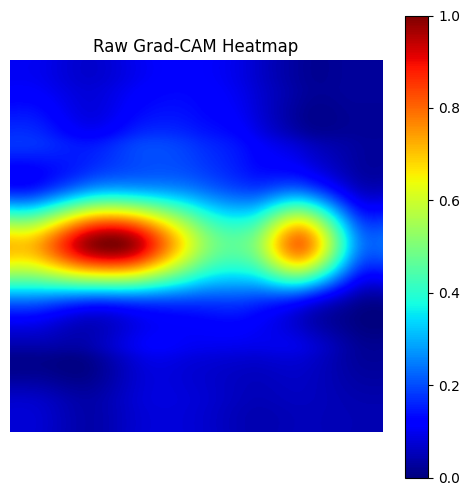

In [23]:
plt.figure(figsize=(6, 6))

plt.imshow(
    cam_resized,
    cmap="jet"
)

plt.colorbar()

plt.title("Raw Grad-CAM Heatmap")

plt.axis("off")

plt.show()